In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 150)

DATA_DIR = Path("data/processed")

In [4]:
movies = pd.read_csv(
    DATA_DIR / "movies.csv",
    dtype={
        "input_tmdb_id": "string",
        "api_movie_id": "string",
        "collection_id": "string"
    },
    low_memory=False
)

cast = pd.read_csv(
    DATA_DIR / "cast.csv",
    dtype={
        "input_tmdb_id": "string",
        "movie_id": "string",
        "actor_id": "string"
    },
    low_memory=False
)

crew = pd.read_csv(
    DATA_DIR / "crew.csv",
    dtype={
        "input_tmdb_id": "string",
        "movie_id": "string",
        "person_id": "string"
    },
    low_memory=False
)

extraction_log = pd.read_csv(
    DATA_DIR / "extraction_log.csv",
    dtype={"input_tmdb_id": "string"},
    low_memory=False
)

datasets = {
    "Movies": movies,
    "Cast": cast,
    "Crew": crew,
    "Extraction Log": extraction_log
}

In [5]:
dataset_overview = pd.DataFrame({
    "Rows": {name: df.shape[0] for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Total Missing": {name: df.isna().sum().sum() for name, df in datasets.items()},
    "Exact Duplicate Rows": {name: df.duplicated().sum() for name, df in datasets.items()}
})

display(dataset_overview)

,Rows,Columns,Total Missing,Exact Duplicate Rows
Movies,119,17,38,0
Cast,8407,7,0,0
Crew,25957,7,0,0
Extraction Log,127,8,256,0


In [6]:
dtype_overview = pd.concat(
    {
        name: df.dtypes.astype(str)
        for name, df in datasets.items()
    },
    axis=1
)

display(dtype_overview)

,Movies,Cast,Crew,Extraction Log
source_row,int64,int64,int64,int64
input_tmdb_id,string,string,string,string
api_movie_id,string,NaN,NaN,NaN
title,str,NaN,NaN,NaN
original_title,str,NaN,NaN,NaN
release_date,str,NaN,NaN,NaN
budget,int64,NaN,NaN,NaN
revenue,int64,NaN,NaN,NaN
runtime,int64,NaN,NaN,NaN
vote_average,float64,NaN,NaN,NaN


In [7]:
missing_summary = pd.concat(
    {
        name: pd.DataFrame({
            "Missing Count": df.isna().sum(),
            "Missing (%)": (df.isna().mean() * 100).round(2)
        })
        for name, df in datasets.items()
    },
    names=["Dataset", "Column"]
)

display(
    missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values(
        ["Dataset", "Missing Count"],
        ascending=[True, False]
    )
)

Missing Count  Missing (%)
Dataset        Column                                         
Extraction Log details_error                  126        99.21
               credits_error                  126        99.21
               input_tmdb_id                    2         1.57
               details_http_status              1         0.79
               credits_http_status              1         0.79
Movies         collection_id                   19        15.97
               collection_name                 19        15.97

In [8]:
log_columns = [
    "source_row",
    "input_tmdb_id",
    "details_http_status",
    "credits_http_status",
    "details_retrieved",
    "credits_retrieved",
    "details_error",
    "credits_error"
]

# Overall extraction outcome patterns
display(
    extraction_log.groupby(
        [
            "details_http_status",
            "credits_http_status",
            "details_retrieved",
            "credits_retrieved"
        ],
        dropna=False
    ).size().reset_index(name="Rows")
)

# Rows that need investigation
issues = extraction_log[
    extraction_log[
        ["input_tmdb_id", "details_http_status", "credits_http_status"]
    ].isna().any(axis=1)
    | ~extraction_log["details_retrieved"]
    | ~extraction_log["credits_retrieved"]
]

display(issues[log_columns].sort_values("source_row"))

,details_http_status,credits_http_status,details_retrieved,credits_retrieved,Rows
0,200.0,200.0,True,True,119
1,404.0,404.0,False,False,7
2,NaN,NaN,False,False,1


,source_row,input_tmdb_id,details_http_status,credits_http_status,details_retrieved,credits_retrieved,details_error,credits_error
16,17,8471293,404.0,404.0,False,False,NaN,NaN
28,29,-1,404.0,404.0,False,False,NaN,NaN
33,34,9412887,404.0,404.0,False,False,NaN,NaN
67,68,<NA>,NaN,NaN,False,False,Skipped: missing TMDb ID,Skipped: missing TMDb ID
71,72,8471294,404.0,404.0,False,False,NaN,NaN
91,92,9412888,404.0,404.0,False,False,NaN,NaN
97,98,7733901,404.0,404.0,False,False,NaN,NaN
109,110,<NA>,404.0,404.0,False,False,NaN,NaN


In [9]:
candidate_ids = pd.read_csv(
    Path("data/raw/id_list.csv"),
    dtype="string",
    low_memory=False
)

print("Original candidate list shape:", candidate_ids.shape)
print("Columns:", candidate_ids.columns.tolist())

# source_row 68 and 110 correspond to positions 67 and 109
display(candidate_ids.iloc[[67, 109]])

Original candidate list shape: (126, 1)
Columns: ['tmdb_id']


,tmdb_id
67,163
109,2501


In [10]:
# IDs associated with HTTP 404 responses
failed_404 = extraction_log[
    extraction_log["details_http_status"].eq(404)
    & extraction_log["credits_http_status"].eq(404)
].copy()

failed_ids = failed_404["input_tmdb_id"].dropna().unique()

# Check whether these IDs appear in the other datasets
cross_dataset_check = pd.DataFrame({
    "Dataset": ["Movies", "Cast", "Crew"],
    "Matching input IDs": [
        movies["input_tmdb_id"].isin(failed_ids).sum(),
        cast["input_tmdb_id"].isin(failed_ids).sum(),
        crew["input_tmdb_id"].isin(failed_ids).sum()
    ],
    "Unique matching IDs": [
        movies.loc[movies["input_tmdb_id"].isin(failed_ids), "input_tmdb_id"].nunique(),
        cast.loc[cast["input_tmdb_id"].isin(failed_ids), "input_tmdb_id"].nunique(),
        crew.loc[crew["input_tmdb_id"].isin(failed_ids), "input_tmdb_id"].nunique()
    ]
})

display(cross_dataset_check)

,Dataset,Matching input IDs,Unique matching IDs
0,Movies,0,0
1,Cast,0,0
2,Crew,0,0


In [11]:
display(
    failed_404[
        ["source_row", "input_tmdb_id",
         "details_http_status", "credits_http_status"]
    ].sort_values("source_row")
)

,source_row,input_tmdb_id,details_http_status,credits_http_status
16,17,8471293,404.0,404.0
28,29,-1,404.0,404.0
33,34,9412887,404.0,404.0
71,72,8471294,404.0,404.0
91,92,9412888,404.0,404.0
97,98,7733901,404.0,404.0
109,110,<NA>,404.0,404.0


In [12]:
# Deliberately empty test record
empty_test = extraction_log[
    extraction_log["details_error"].eq("Skipped: missing TMDb ID")
].copy()

# Records where both API requests returned 404
not_found = extraction_log[
    extraction_log["details_http_status"].eq(404)
    & extraction_log["credits_http_status"].eq(404)
].copy()

# Missing IDs that were not correctly logged as skipped
missing_id_anomaly = extraction_log[
    extraction_log["input_tmdb_id"].isna()
    & ~extraction_log["details_error"].eq("Skipped: missing TMDb ID")
].copy()

print("Deliberate empty test:", len(empty_test))
print("HTTP 404 records:", len(not_found))
print("Missing-ID anomalies:", len(missing_id_anomaly))

Deliberate empty test: 1
HTTP 404 records: 7
Missing-ID anomalies: 1


In [13]:
quarantine = pd.concat(
    [
        empty_test.assign(quarantine_reason="Deliberate empty test"),
        not_found.assign(quarantine_reason="HTTP 404 - Not found"),
        missing_id_anomaly.assign(quarantine_reason="Missing ID - unexplained")
    ],
    ignore_index=True
)

# Preserve the original source row for traceability
quarantine = quarantine.sort_values("source_row")

display(
    quarantine[
        [
            "source_row",
            "input_tmdb_id",
            "details_http_status",
            "credits_http_status",
            "quarantine_reason"
        ]
    ]
)

,source_row,input_tmdb_id,details_http_status,credits_http_status,quarantine_reason
1,17,8471293,404.0,404.0,HTTP 404 - Not found
2,29,-1,404.0,404.0,HTTP 404 - Not found
3,34,9412887,404.0,404.0,HTTP 404 - Not found
0,68,<NA>,NaN,NaN,Deliberate empty test
4,72,8471294,404.0,404.0,HTTP 404 - Not found
5,92,9412888,404.0,404.0,HTTP 404 - Not found
6,98,7733901,404.0,404.0,HTTP 404 - Not found
7,110,<NA>,404.0,404.0,HTTP 404 - Not found
8,110,<NA>,404.0,404.0,Missing ID - unexplained


In [14]:
missing_collection = movies[
    movies["collection_id"].isna()
    & movies["collection_name"].isna()
].copy()

print("Movies missing both collection fields:", len(missing_collection))

display(
    missing_collection[
        [
            "source_row",
            "input_tmdb_id",
            "api_movie_id",
            "title",
            "release_date",
            "budget",
            "revenue",
            "vote_average",
            "vote_count"
        ]
    ].sort_values("title")
)

Movies missing both collection fields: 19


,source_row,input_tmdb_id,api_movie_id,title,release_date,budget,revenue,vote_average,vote_count
86,93,550,550,Fight Club,1999-10-15,63000000,100853753,8.437,33380
73,79,550,550,Fight Club,1999-10-15,63000000,100853753,8.437,33380
68,74,13,13,Forrest Gump,1994-06-23,55000000,677387716,8.462,30919
14,15,769,769,GoodFellas,1990-09-12,25000000,47072327,8.452,15053
37,41,27205,27205,Inception,2010-07-15,160000000,839030630,8.373,40769
115,124,157336,157336,Interstellar,2014-11-04,165000000,746606706,8.500,41950
77,83,77,77,Memento,2000-10-11,9000000,40060108,8.175,17065
93,101,680,680,Pulp Fiction,1994-09-10,8000000,213928762,8.480,31363
6,7,680,680,Pulp Fiction,1994-09-10,8000000,213928762,8.480,31363
57,61,641,641,Requiem for a Dream,2000-10-06,4500000,7390108,8.007,11500


In [15]:
collection_patterns = pd.Series({
    "Both collection fields missing": (
        movies["collection_id"].isna()
        & movies["collection_name"].isna()
    ).sum(),

    "Only collection_id missing": (
        movies["collection_id"].isna()
        & movies["collection_name"].notna()
    ).sum(),

    "Only collection_name missing": (
        movies["collection_id"].notna()
        & movies["collection_name"].isna()
    ).sum(),

    "Both collection fields present": (
        movies["collection_id"].notna()
        & movies["collection_name"].notna()
    ).sum()
}, dtype="int64")

display(collection_patterns.to_frame("Record count"))

print("Total movie records:", len(movies))
print("Unique API movie IDs:", movies["api_movie_id"].nunique())

,Record count
Both collection fields missing,19
Only collection_id missing,0
Only collection_name missing,0
Both collection fields present,100


Total movie records: 119
Unique API movie IDs: 112


In [16]:
# Identify all repeated API movie IDs
duplicate_movies = movies[
    movies["api_movie_id"].duplicated(keep=False)
].copy()

# Count occurrences of each API movie ID
duplicate_movies["occurrence_count"] = (
    duplicate_movies
    .groupby("api_movie_id")["api_movie_id"]
    .transform("size")
)

print("Records belonging to repeated movie IDs:",
      len(duplicate_movies))

print("Distinct repeated API movie IDs:",
      duplicate_movies["api_movie_id"].nunique())

print("\nRepeated movie records:")

display(
    duplicate_movies[
        [
            "source_row",
            "input_tmdb_id",
            "api_movie_id",
            "title",
            "release_date",
            "collection_id",
            "collection_name",
            "budget",
            "revenue",
            "vote_average",
            "vote_count",
            "occurrence_count"
        ]
    ].sort_values(["api_movie_id", "source_row"])
)

Records belonging to repeated movie IDs: 13
Distinct repeated API movie IDs: 6

Repeated movie records:


,source_row,input_tmdb_id,api_movie_id,title,release_date,collection_id,collection_name,budget,revenue,vote_average,vote_count,occurrence_count
0,1,155,155,The Dark Knight,2008-07-16,263,The Dark Knight Collection,185000000,1008480529,8.500,37425,3
84,90,155,155,The Dark Knight,2008-07-16,263,The Dark Knight Collection,185000000,1008480529,8.500,37425,3
87,94,tt0468569,155,The Dark Knight,2008-07-16,263,The Dark Knight Collection,185000000,1008480529,8.540,37424,3
50,54,1891,1891,The Empire Strikes Back,1980-05-20,10,Star Wars Collection,18000000,538400000,8.392,19145,2
83,89,1891,1891,The Empire Strikes Back,1980-05-20,10,Star Wars Collection,18000000,538400000,8.392,19145,2
24,26,278,278,The Shawshank Redemption,1994-09-23,<NA>,NaN,25000000,28341469,8.734,31879,2
55,59,278,278,The Shawshank Redemption,1994-09-23,<NA>,NaN,25000000,28341469,8.734,31879,2
73,79,550,550,Fight Club,1999-10-15,<NA>,NaN,63000000,100853753,8.437,33380,2
86,93,550,550,Fight Club,1999-10-15,<NA>,NaN,63000000,100853753,8.437,33380,2
35,39,603,603,The Matrix,1999-03-31,2344,The Matrix Collection,63000000,463517383,8.263,29296,2


In [17]:
# Compare all columns within repeated API movie IDs

comparison_columns = [
    col for col in movies.columns
    if col not in ["source_row", "input_tmdb_id", "api_movie_id"]
]

duplicate_variation = (
    duplicate_movies
    .groupby("api_movie_id")[comparison_columns]
    .nunique(dropna=False)
)

# Only show fields that vary within at least one repeated ID
varying_columns = duplicate_variation.loc[
    :, duplicate_variation.gt(1).any()
]

print("Fields that differ within repeated movie IDs:")
display(varying_columns)

print("\nNumber of differing fields per repeated ID:")
display(
    varying_columns.gt(1).sum(axis=1).to_frame("Differing fields")
)

Fields that differ within repeated movie IDs:


,vote_average,vote_count
api_movie_id,,
155,2,2
1891,1,1
278,1,1
550,1,1
603,1,1
680,1,1



Number of differing fields per repeated ID:


,Differing fields
api_movie_id,
155,2
1891,0
278,0
550,0
603,0
680,0


In [18]:
dark_knight_records = movies[
    movies["api_movie_id"].eq("155")
].sort_values("source_row")

display(dark_knight_records.T)

,0,84,87
source_row,1,90,94
input_tmdb_id,155,155,tt0468569
api_movie_id,155,155,155
title,The Dark Knight,The Dark Knight,The Dark Knight
original_title,The Dark Knight,The Dark Knight,The Dark Knight
release_date,2008-07-16,2008-07-16,2008-07-16
budget,185000000,185000000,185000000
revenue,1008480529,1008480529,1008480529
runtime,152,152,152
vote_average,8.5,8.5,8.54


In [19]:
# Create a working copy of movies with collection information
franchise_records = movies.loc[
    movies["collection_id"].notna()
    & movies["collection_name"].notna()
].copy()

# Count distinct movies, not candidate occurrences
franchise_summary = (
    franchise_records
    .groupby(
        ["collection_id", "collection_name"],
        as_index=False
    )
    .agg(
        unique_movies=("api_movie_id", "nunique"),
        candidate_occurrences=("api_movie_id", "size"),
        movie_titles=(
            "title",
            lambda x: sorted(x.unique().tolist())
        )
    )
    .sort_values(
        ["unique_movies", "collection_name"],
        ascending=[False, True]
    )
)

# Separate multi-film collections from single-film entries
confirmed_franchises = franchise_summary.loc[
    franchise_summary["unique_movies"] >= 2
].copy()

single_film_collections = franchise_summary.loc[
    franchise_summary["unique_movies"] == 1
].copy()

print("Total collection groups:", len(franchise_summary))
print("Multi-film collections:", len(confirmed_franchises))
print("Single-film collection entries:", len(single_film_collections))

print("\nMULTI-FILM COLLECTIONS")
display(confirmed_franchises)

print("\nSINGLE-FILM COLLECTION ENTRIES")
display(single_film_collections)

Total collection groups: 32
Multi-film collections: 23
Single-film collection entries: 9

MULTI-FILM COLLECTIONS


,collection_id,collection_name,unique_movies,candidate_occurrences,movie_titles
4,1241,Harry Potter Collection,8,8,"[Harry Potter and the Chamber of Secrets, Harr..."
0,10,Star Wars Collection,6,7,"[Return of the Jedi, Star Wars, Star Wars: Epi..."
28,87359,Mission: Impossible Collection,5,5,"[Mission: Impossible, Mission: Impossible - Gh..."
16,295,Pirates of the Caribbean Collection,5,5,"[Pirates of the Caribbean: At World's End, Pir..."
24,8091,Alien Collection,4,4,"[Alien, Alien Resurrection, Aliens, Alien³]"
8,1570,Die Hard Collection,4,4,"[Die Hard, Die Hard 2, Die Hard: With a Vengea..."
26,84,Indiana Jones Collection,4,4,[Indiana Jones and the Kingdom of the Crystal ...
9,2150,Shrek Collection,4,4,"[Shrek, Shrek 2, Shrek Forever After, Shrek th..."
27,86311,The Avengers Collection,4,4,"[Avengers: Age of Ultron, Avengers: Endgame, A..."
23,528,The Terminator Collection,4,4,"[Terminator 2: Judgment Day, Terminator 3: Ris..."



SINGLE-FILM COLLECTION ENTRIES


,collection_id,collection_name,unique_movies,candidate_occurrences,movie_titles
21,422837,Blade Runner Collection,1,1,[Blade Runner]
17,2980,Ghostbusters Collection,1,1,[Ghostbusters]
12,2366,Jaws Collection,1,1,[Jaws]
29,8945,Mad Max Collection,1,1,[Mad Max: Fury Road]
7,137696,"Monsters, Inc. Collection",1,1,"[Monsters, Inc.]"
31,9743,The Hannibal Lecter Collection,1,1,[The Silence of the Lambs]
22,468222,The Incredibles Collection,1,1,[The Incredibles]
30,94032,The Lion King Collection,1,1,[The Lion King]
6,134897,The Smurfs (Theatrical) Collection,1,1,[The Smurfs]


In [20]:
unresolved_collection = movies.loc[
    movies["collection_id"].isna()
    & movies["collection_name"].isna()
].copy()

print("Unresolved collection records:", len(unresolved_collection))
print(
    "Unique unresolved movie IDs:",
    unresolved_collection["api_movie_id"].nunique()
)

Unresolved collection records: 19
Unique unresolved movie IDs: 16


In [21]:
unresolved_summary = (
    unresolved_collection
    .groupby("api_movie_id", as_index=False)
    .agg(
        title=("title", "first"),
        release_date=("release_date", "first"),
        candidate_occurrences=("api_movie_id", "size"),
        source_rows=("source_row", list),
        input_ids=("input_tmdb_id", list)
    )
    .sort_values("title")
)

print("Unique unresolved films:", len(unresolved_summary))
display(unresolved_summary)

Unique unresolved films: 16


,api_movie_id,title,release_date,candidate_occurrences,source_rows,input_ids
11,550,Fight Club,1999-10-15,2,"[79, 93]","[550, 550]"
4,13,Forrest Gump,1994-06-23,1,[74],[13]
14,769,GoodFellas,1990-09-12,1,[15],[769]
7,27205,Inception,2010-07-15,1,[41],[27205]
6,157336,Interstellar,2014-11-04,1,[124],[157336]
15,77,Memento,2000-10-11,1,[83],[77]
13,680,Pulp Fiction,1994-09-10,2,"[7, 101]","[680, 680]"
12,641,Requiem for a Dream,2000-10-06,1,[61],[641]
1,111,Scarface,1983-12-09,1,[57],[111]
9,424,Schindler's List,1993-12-15,1,[112],[424]


In [22]:
# One record per distinct API movie ID
unique_movies = (
    movies
    .sort_values("source_row")
    .drop_duplicates(subset="api_movie_id")
    .copy()
)

# Count distinct candidate movies in each collection
collection_counts = (
    unique_movies[
        unique_movies["collection_id"].notna()
    ]
    .groupby(
        ["collection_id", "collection_name"],
        as_index=False
    )
    .agg(
        unique_movies=("api_movie_id", "nunique")
    )
)

# Identify assignment-level franchise collections
franchise_collection_ids = collection_counts.loc[
    collection_counts["unique_movies"] >= 2,
    "collection_id"
]

# Classify each unique movie
unique_movies["candidate_type"] = np.where(
    unique_movies["collection_id"].isna()
    | ~unique_movies["collection_id"].isin(franchise_collection_ids),
    "Standalone",
    "Franchise"
)

print("Classification:")
display(
    unique_movies["candidate_type"]
    .value_counts()
    .to_frame("Unique movies")
)

print("\nStandalone candidates with collection metadata:")
display(
    unique_movies[
        (unique_movies["candidate_type"] == "Standalone")
        & unique_movies["collection_id"].notna()
    ][
        ["title", "api_movie_id", "collection_id", "collection_name"]
    ].sort_values("title")
)

Classification:


,Unique movies
candidate_type,
Franchise,87
Standalone,25



Standalone candidates with collection metadata:


,title,api_movie_id,collection_id,collection_name
58,Blade Runner,78,422837,Blade Runner Collection
116,Ghostbusters,620,2980,Ghostbusters Collection
91,Jaws,578,2366,Jaws Collection
101,Mad Max: Fury Road,76341,8945,Mad Max Collection
95,"Monsters, Inc.",585,137696,"Monsters, Inc. Collection"
39,The Incredibles,9806,468222,The Incredibles Collection
11,The Lion King,8587,94032,The Lion King Collection
43,The Silence of the Lambs,274,9743,The Hannibal Lecter Collection
54,The Smurfs,41513,134897,The Smurfs (Theatrical) Collection


In [23]:
# Work with unique movie identities, preserving original movies
unique_movies = (
    movies
    .sort_values("source_row")
    .drop_duplicates(subset="api_movie_id")
    .copy()
)

# Keep movies with collection information
collection_members = unique_movies.loc[
    unique_movies["collection_id"].notna()
].copy()

# Build a membership audit
franchise_audit = (
    collection_members
    .groupby(
        ["collection_id", "collection_name"],
        as_index=False
    )
    .agg(
        unique_movies=("api_movie_id", "nunique"),
        movie_titles=("title", lambda x: sorted(x.unique())),
        movie_ids=("api_movie_id", lambda x: sorted(x.unique()))
    )
)

# Only collections with at least two distinct candidate movies
franchise_audit = (
    franchise_audit[
        franchise_audit["unique_movies"] >= 2
    ]
    .sort_values(
        "unique_movies",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Confirmed multi-film candidate collections:",
      len(franchise_audit))

display(franchise_audit)

Confirmed multi-film candidate collections: 23


,collection_id,collection_name,unique_movies,movie_titles,movie_ids
0,1241,Harry Potter Collection,8,"[Harry Potter and the Chamber of Secrets, Harr...","[12444, 12445, 671, 672, 673, 674, 675, 767]"
1,10,Star Wars Collection,6,"[Return of the Jedi, Star Wars, Star Wars: Epi...","[11, 1891, 1892, 1893, 1894, 1895]"
2,295,Pirates of the Caribbean Collection,5,"[Pirates of the Caribbean: At World's End, Pir...","[166426, 1865, 22, 285, 58]"
3,87359,Mission: Impossible Collection,5,"[Mission: Impossible, Mission: Impossible - Gh...","[177677, 56292, 954, 955, 956]"
4,8091,Alien Collection,4,"[Alien, Alien Resurrection, Aliens, Alien³]","[348, 679, 8077, 8078]"
5,1570,Die Hard Collection,4,"[Die Hard, Die Hard 2, Die Hard: With a Vengea...","[1571, 1572, 1573, 562]"
6,10194,Toy Story Collection,4,"[Toy Story, Toy Story 2, Toy Story 3, Toy Stor...","[10193, 301528, 862, 863]"
7,528,The Terminator Collection,4,"[Terminator 2: Judgment Day, Terminator 3: Ris...","[218, 280, 296, 534]"
8,84,Indiana Jones Collection,4,[Indiana Jones and the Kingdom of the Crystal ...,"[217, 85, 87, 89]"
9,86311,The Avengers Collection,4,"[Avengers: Age of Ultron, Avengers: Endgame, A...","[24428, 299534, 299536, 99861]"


In [24]:
# Work with unique movie identities
financial_data = (
    movies
    .sort_values("source_row")
    .drop_duplicates(subset="api_movie_id")
    .copy()
)

financial_columns = ["budget", "revenue"]

# Explicit numeric conversion for the analysis copy
for col in financial_columns:
    financial_data[col] = pd.to_numeric(
        financial_data[col],
        errors="coerce"
    ).astype("Float64")

# Financial data quality summary
financial_quality = pd.DataFrame({
    "Missing": financial_data[financial_columns].isna().sum(),
    "Zero": financial_data[financial_columns].eq(0).sum(),
    "Negative": financial_data[financial_columns].lt(0).sum(),
    "Available": financial_data[financial_columns].notna().sum()
})

display(financial_quality)

print("Unique movies:", len(financial_data))

,Missing,Zero,Negative,Available
budget,0,0,0,112
revenue,0,0,0,112


Unique movies: 112


In [25]:
# Historical financial performance indicators

financial_data["estimated_profit"] = (
    financial_data["revenue"] -
    financial_data["budget"]
)

financial_data["roi_pct"] = (
    financial_data["estimated_profit"] /
    financial_data["budget"]
) * 100

financial_data["revenue_budget_multiple"] = (
    financial_data["revenue"] /
    financial_data["budget"]
)

financial_data["release_year"] = pd.to_datetime(
    financial_data["release_date"],
    errors="coerce"
).dt.year

# Inspect the resulting financial indicators

display(
    financial_data[
        [
            "title",
            "release_year",
            "budget",
            "revenue",
            "estimated_profit",
            "roi_pct",
            "revenue_budget_multiple",
            "vote_average",
            "vote_count"
        ]
    ].sort_values(
        "revenue_budget_multiple",
        ascending=False
    )
)

,title,release_year,budget,revenue,estimated_profit,roi_pct,revenue_budget_multiple,vote_average,vote_count
23,Star Wars,1977,11000000.0,775398007.0,764398007.0,6949.072791,70.490728,8.206,23191
91,Jaws,1975,7000000.0,470653000.0,463653000.0,6623.614286,67.236143,7.687,12044
61,The Godfather,1972,6000000.0,245066411.0,239066411.0,3984.440183,40.844402,8.689,24013
69,"The Good, the Bad and the Ugly",1966,1200000.0,38900000.0,37700000.0,3141.666667,32.416667,8.468,10162
50,The Empire Strikes Back,1980,18000000.0,538400000.0,520400000.0,2891.111111,29.911111,8.392,19145
...,...,...,...,...,...,...,...,...,...
109,Terminator Salvation,2009,200000000.0,371353001.0,171353001.0,85.676501,1.856765,6.108,7366
57,Requiem for a Dream,2000,4500000.0,7390108.0,2890108.0,64.224622,1.642246,8.007,11500
73,Fight Club,1999,63000000.0,100853753.0,37853753.0,60.085322,1.600853,8.437,33380
58,Blade Runner,1982,28000000.0,41722424.0,13722424.0,49.008657,1.490087,7.937,15655


In [26]:
# Identify collection IDs represented by at least
# two distinct movies in the candidate dataset.

collection_counts = (
    financial_data
    .dropna(subset=["collection_id"])
    .groupby(["collection_id", "collection_name"])
    ["api_movie_id"]
    .nunique()
    .reset_index(name="unique_movies_in_candidates")
)

# Qualifying franchise collections
multi_film_collection_ids = (
    collection_counts.loc[
        collection_counts["unique_movies_in_candidates"] >= 2,
        "collection_id"
    ]
)

# Assign acquisition category
financial_data["acquisition_type"] = (
    financial_data["collection_id"]
    .isin(multi_film_collection_ids)
    .map({True: "Franchise", False: "Standalone"})
)

# Inspect classification
display(
    financial_data[
        [
            "title",
            "api_movie_id",
            "collection_id",
            "collection_name",
            "acquisition_type"
        ]
    ].sort_values(
        ["acquisition_type", "collection_name", "title"]
    )
)

print("\nClassification counts:")
print(financial_data["acquisition_type"].value_counts())

,title,api_movie_id,collection_id,collection_name,acquisition_type
66,Alien,348,8091,Alien Collection,Franchise
118,Alien Resurrection,8078,8091,Alien Collection,Franchise
19,Aliens,679,8091,Alien Collection,Franchise
4,Alien³,8077,8091,Alien Collection,Franchise
15,Back to the Future,105,264,Back to the Future Collection,Franchise
...,...,...,...,...,...
36,The Departed,1422,<NA>,NaN,Standalone
69,"The Good, the Bad and the Ugly",429,<NA>,NaN,Standalone
51,The Prestige,1124,<NA>,NaN,Standalone
24,The Shawshank Redemption,278,<NA>,NaN,Standalone



Classification counts:
acquisition_type
Franchise     87
Standalone    25
Name: count, dtype: int64


In [27]:
# ============================================================
# BUILD ACQUISITION UNITS
# 1. Franchise bundles = grouped collection films
# 2. Standalone acquisitions = individual films
# ============================================================

# ----------------------------
# A. Build franchise bundles
# ----------------------------

franchise_units = (
    financial_data[
        financial_data["acquisition_type"] == "Franchise"
    ]
    .groupby(
        ["collection_id", "collection_name"],
        as_index=False
    )
    .agg(
        titles=("title", lambda x: list(x)),
        movie_count=("api_movie_id", "nunique"),
        total_budget=("budget", "sum"),
        total_revenue=("revenue", "sum"),
        total_profit=("estimated_profit", "sum"),
        average_rating=("vote_average", "mean"),
        total_votes=("vote_count", "sum"),
        earliest_year=("release_year", "min"),
        latest_year=("release_year", "max")
    )
)

franchise_units["acquisition_type"] = "Franchise"


# ----------------------------
# B. Build standalone units
# ----------------------------

standalone_movies = financial_data[
    financial_data["acquisition_type"] == "Standalone"
].copy()

standalone_units = pd.DataFrame({
    "collection_name": standalone_movies["title"].values,
    "titles": [[title] for title in standalone_movies["title"]],
    "movie_count": 1,
    "total_budget": standalone_movies["budget"].values,
    "total_revenue": standalone_movies["revenue"].values,
    "total_profit": standalone_movies["estimated_profit"].values,
    "average_rating": standalone_movies["vote_average"].values,
    "total_votes": standalone_movies["vote_count"].values,
    "earliest_year": standalone_movies["release_year"].values,
    "latest_year": standalone_movies["release_year"].values,
    "acquisition_type": "Standalone"
})


# ----------------------------
# C. Standardize the columns
# ----------------------------

common_columns = [
    "collection_name",
    "titles",
    "movie_count",
    "total_budget",
    "total_revenue",
    "total_profit",
    "average_rating",
    "total_votes",
    "earliest_year",
    "latest_year",
    "acquisition_type"
]

franchise_units = franchise_units[common_columns]
standalone_units = standalone_units[common_columns]


# ----------------------------
# D. Combine acquisition units
# ----------------------------

acquisition_units = pd.concat(
    [franchise_units, standalone_units],
    ignore_index=True
)


# ----------------------------
# E. Calculate financial indicators
# ----------------------------

acquisition_units["revenue_budget_multiple"] = (
    acquisition_units["total_revenue"] /
    acquisition_units["total_budget"]
)

acquisition_units["roi_pct"] = (
    acquisition_units["total_profit"] /
    acquisition_units["total_budget"]
) * 100


# ----------------------------
# F. Inspect results
# ----------------------------

display(
    acquisition_units.sort_values(
        "revenue_budget_multiple",
        ascending=False
    )
)

print("Total acquisition units:", len(acquisition_units))

print(
    "Franchise units:",
    (acquisition_units["acquisition_type"] == "Franchise").sum()
)

print(
    "Standalone units:",
    (acquisition_units["acquisition_type"] == "Standalone").sum()
)

,collection_name,titles,movie_count,total_budget,total_revenue,total_profit,average_rating,total_votes,earliest_year,latest_year,acquisition_type,revenue_budget_multiple,roi_pct
42,Jaws,[Jaws],1,7000000.0,470653000.0,463653000.0,7.687000,12044,1975,1975,Standalone,67.236143,6623.614286
39,"The Good, the Bad and the Ugly","[The Good, the Bad and the Ugly]",1,1200000.0,38900000.0,37700000.0,8.468000,10162,1966,1966,Standalone,32.416667,3141.666667
23,Pulp Fiction,[Pulp Fiction],1,8000000.0,213928762.0,205928762.0,8.480000,31363,1994,1994,Standalone,26.741095,2574.109525
24,The Lion King,[The Lion King],1,45000000.0,763455561.0,718455561.0,8.250000,20427,1994,1994,Standalone,16.965679,1596.567913
45,Schindler's List,[Schindler's List],1,22000000.0,321365567.0,299365567.0,8.570000,18203,1993,1993,Standalone,14.607526,1360.752577
37,Spirited Away,[Spirited Away],1,19000000.0,274925095.0,255925095.0,8.537000,19243,2001,2001,Standalone,14.469742,1346.974184
30,The Silence of the Lambs,[The Silence of the Lambs],1,19000000.0,272742922.0,253742922.0,8.346000,18876,1991,1991,Standalone,14.354891,1335.489063
38,Forrest Gump,[Forrest Gump],1,55000000.0,677387716.0,622387716.0,8.462000,30919,1994,1994,Standalone,12.31614,1131.614029
2,The Lord of the Rings Collection,"[The Lord of the Rings: The Two Towers, The Lo...",3,266000000.0,2916544743.0,2650544743.0,8.469333,81777,2001,2003,Franchise,10.964454,996.445392
0,Star Wars Collection,"[Return of the Jedi, Star Wars, Star Wars: Epi...",6,409350000.0,4432411744.0,4023061744.0,7.527833,106791,1977,2005,Franchise,10.827927,982.792658


Total acquisition units: 48
Franchise units: 23
Standalone units: 25


In [28]:
# Compare acquisition types across all years

comparison_all_years = (
    acquisition_units
    .groupby("acquisition_type")
    .agg(
        acquisition_units=("collection_name", "count"),
        total_movies=("movie_count", "sum"),
        avg_profit=("total_profit", "mean"),
        median_profit=("total_profit", "median"),
        avg_roi=("roi_pct", "mean"),
        median_roi=("roi_pct", "median"),
        avg_revenue_budget_multiple=("revenue_budget_multiple", "mean"),
        median_revenue_budget_multiple=("revenue_budget_multiple", "median"),
        avg_rating=("average_rating", "mean"),
        median_rating=("average_rating", "median"),
        avg_votes=("total_votes", "mean"),
        avg_movie_count=("movie_count", "mean")
    )
    .round(2)
)

display(comparison_all_years)

,acquisition_units,total_movies,avg_profit,median_profit,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating,avg_votes,avg_movie_count
acquisition_type,,,,,,,,,,,,
Franchise,23,87,2092388227.83,1816874038.0,497.46,455.11,5.97,5.55,7.45,7.37,62919.17,3.78
Standalone,25,25,275636100.92,253742922.0,947.99,400.0,10.48,5.0,8.10,8.21,20728.80,1.00


In [29]:
# Add profit per movie to the acquisition-unit dataset

acquisition_units["profit_per_movie"] = (
    acquisition_units["total_profit"] /
    acquisition_units["movie_count"]
)

# Compare acquisition strategies using key financial and audience metrics

strategy_comparison = (
    acquisition_units
    .groupby("acquisition_type")
    .agg(
        acquisition_units=("collection_name", "count"),
        total_movies=("movie_count", "sum"),

        avg_profit_per_unit=("total_profit", "mean"),
        median_profit_per_unit=("total_profit", "median"),

        avg_profit_per_movie=("profit_per_movie", "mean"),
        median_profit_per_movie=("profit_per_movie", "median"),

        avg_roi=("roi_pct", "mean"),
        median_roi=("roi_pct", "median"),

        avg_revenue_budget_multiple=("revenue_budget_multiple", "mean"),
        median_revenue_budget_multiple=("revenue_budget_multiple", "median"),

        avg_rating=("average_rating", "mean"),
        median_rating=("average_rating", "median")
    )
)

display(strategy_comparison.round(2))

,acquisition_units,total_movies,avg_profit_per_unit,median_profit_per_unit,avg_profit_per_movie,median_profit_per_movie,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating
acquisition_type,,,,,,,,,,,,
Franchise,23,87,2092388227.83,1816874038.0,523394240.2,567314236.33,497.46,455.11,5.97,5.55,7.45,7.37
Standalone,25,25,275636100.92,253742922.0,275636100.92,253742922.0,947.99,400.0,10.48,5.0,8.10,8.21


In [30]:
# Compare franchise and standalone acquisition units:
# 1. All release years
# 2. 2000 onward

comparison_data = acquisition_units.copy()

# Ensure year columns are numeric
comparison_data["earliest_year"] = pd.to_numeric(
    comparison_data["earliest_year"],
    errors="coerce"
)

comparison_data["latest_year"] = pd.to_numeric(
    comparison_data["latest_year"],
    errors="coerce"
)

# Define the two analysis periods
all_years = comparison_data.copy()

post_2000 = comparison_data[
    comparison_data["earliest_year"] >= 2000
].copy()

# Function to summarize acquisition types
def summarize_acquisitions(data, period):

    summary = (
        data.groupby("acquisition_type")
        .agg(
            acquisition_units=("collection_name", "count"),
            total_movies=("movie_count", "sum"),
            avg_profit_per_unit=("total_profit", "mean"),
            median_profit_per_unit=("total_profit", "median"),
            avg_roi=("roi_pct", "mean"),
            median_roi=("roi_pct", "median"),
            avg_revenue_budget_multiple=(
                "revenue_budget_multiple", "mean"
            ),
            median_revenue_budget_multiple=(
                "revenue_budget_multiple", "median"
            ),
            avg_rating=("average_rating", "mean"),
            median_rating=("average_rating", "median")
        )
    )

    summary["period"] = period

    return summary.reset_index()


# Generate comparisons
all_years_summary = summarize_acquisitions(
    all_years, "All years"
)

post_2000_summary = summarize_acquisitions(
    post_2000, "2000 onward"
)

comparison_results = pd.concat(
    [all_years_summary, post_2000_summary],
    ignore_index=True
)

# Organize display
comparison_results = comparison_results[
    ["period", "acquisition_type",
     "acquisition_units", "total_movies",
     "avg_profit_per_unit", "median_profit_per_unit",
     "avg_roi", "median_roi",
     "avg_revenue_budget_multiple",
     "median_revenue_budget_multiple",
     "avg_rating", "median_rating"]
]

display(comparison_results.round(2))


,period,acquisition_type,acquisition_units,total_movies,avg_profit_per_unit,median_profit_per_unit,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating
0,All years,Franchise,23,87,2092388227.83,1816874038.0,497.46,455.11,5.97,5.55,7.45,7.37
1,All years,Standalone,25,25,275636100.92,253742922.0,947.99,400.0,10.48,5.0,8.10,8.21
2,2000 onward,Franchise,12,44,2597695978.33,2035104057.0,471.51,408.13,5.72,5.08,7.52,7.43
3,2000 onward,Standalone,12,12,325417964.42,298618477.5,389.36,348.8,4.89,4.49,7.92,8.14


In [31]:
# Inspect the acquisition units with the key metrics we will use
candidate_ranking = acquisition_units[
    [
        "collection_name",
        "titles",
        "movie_count",
        "total_budget",
        "total_revenue",
        "total_profit",
        "roi_pct",
        "revenue_budget_multiple",
        "average_rating",
        "total_votes",
        "earliest_year",
        "latest_year",
        "acquisition_type"
    ]
].copy()

display(
    candidate_ranking.sort_values(
        "total_profit",
        ascending=False
    )
)

,collection_name,titles,movie_count,total_budget,total_revenue,total_profit,roi_pct,revenue_budget_multiple,average_rating,total_votes,earliest_year,latest_year,acquisition_type
21,The Avengers Collection,"[Avengers: Endgame, The Avengers, Avengers: In...",4,1111000000.0,7919284026.0,6808284026.0,612.806843,7.128068,7.952500,128645,2012,2019,Franchise
4,Harry Potter Collection,"[Harry Potter and the Prisoner of Azkaban, Har...",8,1280000000.0,7759777709.0,6479777709.0,506.232634,6.062326,7.825000,188854,2001,2011,Franchise
0,Star Wars Collection,"[Return of the Jedi, Star Wars, Star Wars: Epi...",6,409350000.0,4432411744.0,4023061744.0,982.792658,10.827927,7.527833,106791,1977,2005,Franchise
13,Pirates of the Caribbean Collection,"[Pirates of the Caribbean: Dead Man's Chest, P...",5,1249000000.0,4525525744.0,3276525744.0,262.331925,3.623319,7.150600,85765,2003,2017,Franchise
2,The Lord of the Rings Collection,"[The Lord of the Rings: The Two Towers, The Lo...",3,266000000.0,2916544743.0,2650544743.0,996.445392,10.964454,8.469333,81777,2001,2003,Franchise
1,Toy Story Collection,"[Toy Story 2, Toy Story, Toy Story 4, Toy Stor...",4,495000000.0,3039690868.0,2544690868.0,514.078963,6.14079,7.722500,64074,1995,2019,Franchise
7,Shrek Collection,"[Shrek the Third, Shrek, Shrek 2, Shrek Foreve...",4,535000000.0,2983130036.0,2448130036.0,457.594399,5.575944,6.966500,51984,2001,2010,Franchise
3,The Hobbit Collection,"[The Hobbit: The Battle of the Five Armies, Th...",3,750000000.0,2935523356.0,2185523356.0,291.403114,3.914031,7.437000,51195,2012,2014,Franchise
22,Mission: Impossible Collection,"[Mission: Impossible II, Mission: Impossible -...",5,650000000.0,2779994012.0,2129994012.0,327.691386,4.276914,6.859000,47751,1996,2015,Franchise
5,Iron Man Collection,"[Iron Man 2, Iron Man, Iron Man 3]",3,540000000.0,2424684758.0,1884684758.0,349.015696,4.490157,7.152000,76649,2008,2013,Franchise


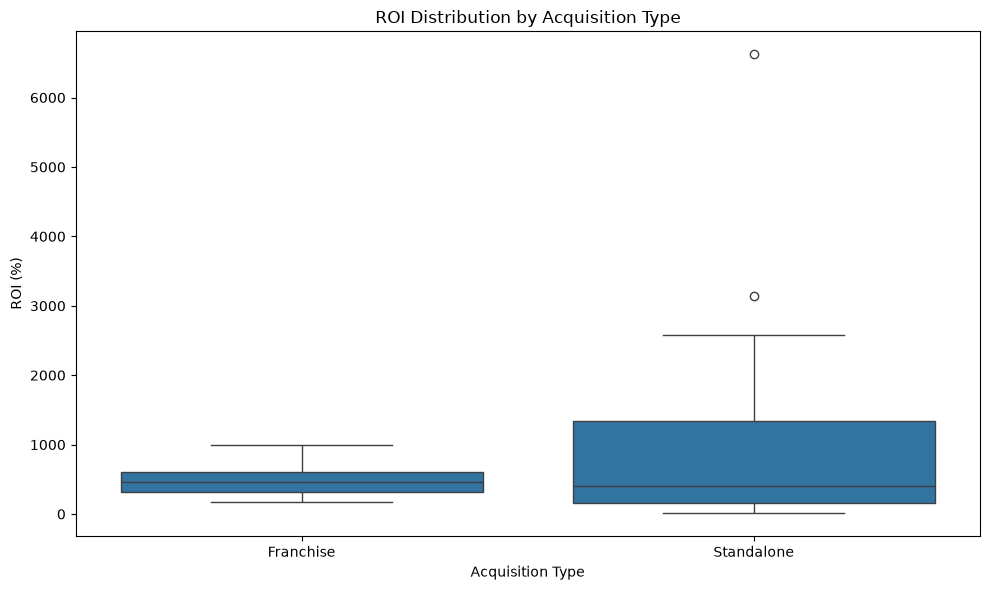

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare ROI distributions at acquisition-unit level
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=acquisition_units,
    x="acquisition_type",
    y="roi_pct"
)

plt.title("ROI Distribution by Acquisition Type")
plt.ylabel("ROI (%)")
plt.xlabel("Acquisition Type")
plt.tight_layout()
plt.show()

In [33]:
roi_distribution = (
    acquisition_units
    .groupby("acquisition_type")["roi_pct"]
    .describe()
    .round(2)
)

display(roi_distribution)


,count,mean,std,min,25%,50%,75%,max
acquisition_type,,,,,,,,
Franchise,23.0,497.46,239.16,175.87,314.6,455.11,611.93,996.45
Standalone,25.0,947.99,1432.55,13.37,164.09,400.0,1335.49,6623.61


In [34]:
# Examine the highest ROI acquisition units
roi_outliers = (
    acquisition_units
    .sort_values("roi_pct", ascending=False)
    [["collection_name",
      "titles",
      "acquisition_type",
      "total_budget",
      "total_revenue",
      "total_profit",
      "roi_pct",
      "revenue_budget_multiple",
      "earliest_year",
      "latest_year"]
    ]
)

display(roi_outliers.head(10))

,collection_name,titles,acquisition_type,total_budget,total_revenue,total_profit,roi_pct,revenue_budget_multiple,earliest_year,latest_year
42,Jaws,[Jaws],Standalone,7000000.0,470653000.0,463653000.0,6623.614286,67.236143,1975,1975
39,"The Good, the Bad and the Ugly","[The Good, the Bad and the Ugly]",Standalone,1200000.0,38900000.0,37700000.0,3141.666667,32.416667,1966,1966
23,Pulp Fiction,[Pulp Fiction],Standalone,8000000.0,213928762.0,205928762.0,2574.109525,26.741095,1994,1994
24,The Lion King,[The Lion King],Standalone,45000000.0,763455561.0,718455561.0,1596.567913,16.965679,1994,1994
45,Schindler's List,[Schindler's List],Standalone,22000000.0,321365567.0,299365567.0,1360.752577,14.607526,1993,1993
37,Spirited Away,[Spirited Away],Standalone,19000000.0,274925095.0,255925095.0,1346.974184,14.469742,2001,2001
30,The Silence of the Lambs,[The Silence of the Lambs],Standalone,19000000.0,272742922.0,253742922.0,1335.489063,14.354891,1991,1991
38,Forrest Gump,[Forrest Gump],Standalone,55000000.0,677387716.0,622387716.0,1131.614029,12.31614,1994,1994
2,The Lord of the Rings Collection,"[The Lord of the Rings: The Two Towers, The Lo...",Franchise,266000000.0,2916544743.0,2650544743.0,996.445392,10.964454,2001,2003
0,Star Wars Collection,"[Return of the Jedi, Star Wars, Star Wars: Epi...",Franchise,409350000.0,4432411744.0,4023061744.0,982.792658,10.827927,1977,2005


In [35]:
# Define the two analysis periods
all_years = acquisition_units.copy()

modern_units = acquisition_units[
    acquisition_units["earliest_year"] >= 2000
].copy()

# Comparison summary function
def compare_acquisition_types(data, period_name):

    summary = (
        data.groupby("acquisition_type")
        .agg(
            acquisition_units=("collection_name", "count"),
            total_movies=("movie_count", "sum"),
            avg_profit_per_unit=("total_profit", "mean"),
            median_profit_per_unit=("total_profit", "median"),
            avg_roi=("roi_pct", "mean"),
            median_roi=("roi_pct", "median"),
            avg_revenue_budget_multiple=("revenue_budget_multiple", "mean"),
            median_revenue_budget_multiple=("revenue_budget_multiple", "median"),
            avg_rating=("average_rating", "mean"),
            median_rating=("average_rating", "median")
        )
        .reset_index()
    )

    summary.insert(0, "period", period_name)

    return summary


# Compare both periods
comparison = pd.concat(
    [
        compare_acquisition_types(all_years, "All years"),
        compare_acquisition_types(modern_units, "2000 onward")
    ],
    ignore_index=True
)

display(comparison.round(2))

,period,acquisition_type,acquisition_units,total_movies,avg_profit_per_unit,median_profit_per_unit,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating
0,All years,Franchise,23,87,2092388227.83,1816874038.0,497.46,455.11,5.97,5.55,7.45,7.37
1,All years,Standalone,25,25,275636100.92,253742922.0,947.99,400.0,10.48,5.0,8.10,8.21
2,2000 onward,Franchise,12,44,2597695978.33,2035104057.0,471.51,408.13,5.72,5.08,7.52,7.43
3,2000 onward,Standalone,12,12,325417964.42,298618477.5,389.36,348.8,4.89,4.49,7.92,8.14


In [36]:
# Rank franchise and standalone acquisition units separately

ranking_columns = [
    "collection_name",
    "titles",
    "movie_count",
    "total_budget",
    "total_revenue",
    "total_profit",
    "roi_pct",
    "revenue_budget_multiple",
    "average_rating",
    "total_votes",
    "earliest_year",
    "latest_year"
]

# Modern-period candidates
modern_candidates = acquisition_units[
    acquisition_units["earliest_year"] >= 2000
].copy()

# Top 10 franchises
top_franchises = (
    modern_candidates[
        modern_candidates["acquisition_type"] == "Franchise"
    ]
    .sort_values(
        ["roi_pct", "average_rating"],
        ascending=False
    )
)

# Top 10 standalone films
top_standalones = (
    modern_candidates[
        modern_candidates["acquisition_type"] == "Standalone"
    ]
    .sort_values(
        ["roi_pct", "average_rating"],
        ascending=False
    )
)

print("TOP FRANCHISE CANDIDATES")
display(top_franchises[ranking_columns].head(10))

print("TOP STANDALONE CANDIDATES")
display(top_standalones[ranking_columns].head(10))


TOP FRANCHISE CANDIDATES


,collection_name,titles,movie_count,total_budget,total_revenue,total_profit,roi_pct,revenue_budget_multiple,average_rating,total_votes,earliest_year,latest_year
2,The Lord of the Rings Collection,"[The Lord of the Rings: The Two Towers, The Lo...",3,266000000.0,2916544743.0,2650544743.0,996.445392,10.964454,8.469333,81777,2001,2003
19,Ice Age Collection,"[Ice Age: Dawn of the Dinosaurs, Ice Age, Ice ...",3,229000000.0,1930942709.0,1701942709.0,743.206423,8.432064,6.968333,34714,2002,2009
21,The Avengers Collection,"[Avengers: Endgame, The Avengers, Avengers: In...",4,1111000000.0,7919284026.0,6808284026.0,612.806843,7.128068,7.952500,128645,2012,2019
4,Harry Potter Collection,"[Harry Potter and the Prisoner of Azkaban, Har...",8,1280000000.0,7759777709.0,6479777709.0,506.232634,6.062326,7.825000,188854,2001,2011
7,Shrek Collection,"[Shrek the Third, Shrek, Shrek 2, Shrek Foreve...",4,535000000.0,2983130036.0,2448130036.0,457.594399,5.575944,6.966500,51984,2001,2010
12,Kill Bill Collection,"[Kill Bill: Vol. 1, Kill Bill: Vol. 2]",2,60000000.0,333065537.0,273065537.0,455.109228,5.551092,7.920500,35445,2003,2004
15,The Bourne Collection,"[The Bourne Supremacy, The Bourne Ultimatum, T...",3,205000000.0,945358579.0,740358579.0,361.150526,4.611505,7.426667,27909,2002,2007
5,Iron Man Collection,"[Iron Man 2, Iron Man, Iron Man 3]",3,540000000.0,2424684758.0,1884684758.0,349.015696,4.490157,7.152000,76649,2008,2013
10,The Dark Knight Collection,"[The Dark Knight, The Dark Knight Rises, Batma...",3,585000000.0,2463740489.0,1878740489.0,321.15222,4.211522,8.011333,86323,2005,2012
14,Ocean's Collection,"[Ocean's Eleven, Ocean's Twelve, Ocean's Thirt...",3,280000000.0,1124774054.0,844774054.0,301.705019,4.01705,6.926000,28622,2001,2007


TOP STANDALONE CANDIDATES


,collection_name,titles,movie_count,total_budget,total_revenue,total_profit,roi_pct,revenue_budget_multiple,average_rating,total_votes,earliest_year,latest_year
37,Spirited Away,[Spirited Away],1,19000000.0,274925095.0,255925095.0,1346.974184,14.469742,8.537,19243,2001,2001
29,The Incredibles,[The Incredibles],1,92000000.0,631442092.0,539442092.0,586.3501,6.863501,7.730,19557,2004,2004
28,Inception,[Inception],1,160000000.0,839030630.0,679030630.0,424.394144,5.243941,8.373,40769,2010,2010
33,The Smurfs,[The Smurfs],1,110000000.0,563749323.0,453749323.0,412.499385,5.124994,5.753,4137,2011,2011
43,"Monsters, Inc.","[Monsters, Inc.]",1,130000000.0,650000000.0,520000000.0,400.0,5.0,7.860,20536,2001,2001
46,Interstellar,[Interstellar],1,165000000.0,746606706.0,581606706.0,352.488913,4.524889,8.500,41950,2014,2014
41,Memento,[Memento],1,9000000.0,40060108.0,31060108.0,345.112311,4.451123,8.175,17065,2000,2000
27,The Departed,[The Departed],1,90000000.0,291465000.0,201465000.0,223.85,3.2385,8.160,16955,2006,2006
34,WALL·E,[WALL·E],1,180000000.0,521311860.0,341311860.0,189.6177,2.896177,8.129,21213,2008,2008
31,The Prestige,[The Prestige],1,40000000.0,109676311.0,69676311.0,174.190777,2.741908,8.212,18487,2006,2006


In [38]:
# Create a working copy for acquisition scoring
scoring_data = acquisition_units.copy()

# Log-transform highly skewed financial and popularity variables
scoring_data["log_profit"] = np.log1p(
    scoring_data["total_profit"].clip(lower=0)
)

scoring_data["log_votes"] = np.log1p(
    scoring_data["total_votes"].clip(lower=0)
)

scoring_data["log_revenue_multiple"] = np.log1p(
    scoring_data["revenue_budget_multiple"].clip(lower=0)
)

# Normalize the scoring variables
from sklearn.preprocessing import MinMaxScaler

scoring_features = [
    "log_profit",
    "log_revenue_multiple",
    "average_rating",
    "log_votes",
    "movie_count"
]

scaler = MinMaxScaler()

normalized_scores = scaler.fit_transform(
    scoring_data[scoring_features]
)

normalized_scores = pd.DataFrame(
    normalized_scores,
    columns=scoring_features,
    index=scoring_data.index
)

# Define transparent initial weights
weights = {
    "log_profit": 0.25,
    "log_revenue_multiple": 0.25,
    "average_rating": 0.20,
    "log_votes": 0.15,
    "movie_count": 0.15
}

# Calculate weighted acquisition score
scoring_data["acquisition_score"] = sum(
    normalized_scores[feature] * weight
    for feature, weight in weights.items()
) * 100

# Rank acquisition opportunities
scoring_data = scoring_data.sort_values(
    "acquisition_score",
    ascending=False
).reset_index(drop=True)

# Display top opportunities
display(
    scoring_data[
        [
            "collection_name",
            "acquisition_type",
            "movie_count",
            "total_profit",
            "roi_pct",
            "average_rating",
            "total_votes",
            "acquisition_score"
        ]
    ].head(15).round(2)
)

,collection_name,acquisition_type,movie_count,total_profit,roi_pct,average_rating,total_votes,acquisition_score
0,Harry Potter Collection,Franchise,8,6479777709.0,506.23,7.82,188854,77.38
1,Star Wars Collection,Franchise,6,4023061744.0,982.79,7.53,106791,71.05
2,The Avengers Collection,Franchise,4,6808284026.0,612.81,7.95,128645,69.33
3,The Lord of the Rings Collection,Franchise,3,2650544743.0,996.45,8.47,81777,68.63
4,Toy Story Collection,Franchise,4,2544690868.0,514.08,7.72,64074,60.95
5,The Dark Knight Collection,Franchise,3,1878740489.0,321.15,8.01,86323,58.66
6,Jaws,Standalone,1,463653000.0,6623.61,7.69,12044,58.52
7,Pulp Fiction,Standalone,1,205928762.0,2574.11,8.48,31363,58.49
8,Back to the Future Collection,Franchise,3,870485632.0,879.28,7.87,49352,58.29
9,Pirates of the Caribbean Collection,Franchise,5,3276525744.0,262.33,7.15,85765,58.07


In [39]:
# Create a fresh scoring dataset
robust_scores = acquisition_units.copy()

# Use percentile ranks to reduce sensitivity to extreme values
robust_scores["profit_score"] = (
    robust_scores["total_profit"].rank(pct=True) * 100
)

robust_scores["financial_efficiency_score"] = (
    robust_scores["revenue_budget_multiple"].rank(pct=True) * 100
)

robust_scores["rating_score"] = (
    robust_scores["average_rating"].rank(pct=True) * 100
)

robust_scores["popularity_score"] = (
    robust_scores["total_votes"].rank(pct=True) * 100
)

robust_scores["content_breadth_score"] = (
    robust_scores["movie_count"].rank(pct=True) * 100
)

# Core score: excludes movie count
robust_scores["core_score"] = (
    0.30 * robust_scores["profit_score"] +
    0.30 * robust_scores["financial_efficiency_score"] +
    0.20 * robust_scores["rating_score"] +
    0.20 * robust_scores["popularity_score"]
)

# Portfolio score: includes a modest content-volume contribution
robust_scores["portfolio_score"] = (
    0.90 * robust_scores["core_score"] +
    0.10 * robust_scores["content_breadth_score"]
)

# Rank opportunities within their acquisition categories
robust_scores["type_rank"] = (
    robust_scores.groupby("acquisition_type")["core_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Top 10 franchise opportunities
print("TOP 10 FRANCHISE OPPORTUNITIES")

display(
    robust_scores[
        robust_scores["acquisition_type"] == "Franchise"
    ]
    .sort_values("core_score", ascending=False)
    [[
        "collection_name",
        "movie_count",
        "total_profit",
        "roi_pct",
        "average_rating",
        "core_score",
        "portfolio_score",
        "type_rank"
    ]]
    .head(10)
    .round(2)
)

# Top 10 standalone opportunities
print("TOP 10 STANDALONE OPPORTUNITIES")

display(
    robust_scores[
        robust_scores["acquisition_type"] == "Standalone"
    ]
    .sort_values("core_score", ascending=False)
    [[
        "collection_name",
        "movie_count",
        "total_profit",
        "roi_pct",
        "average_rating",
        "core_score",
        "portfolio_score",
        "type_rank"
    ]]
    .head(10)
    .round(2)
)

TOP 10 FRANCHISE OPPORTUNITIES


,collection_name,movie_count,total_profit,roi_pct,average_rating,core_score,portfolio_score,type_rank
2,The Lord of the Rings Collection,3,2650544743.0,996.45,8.47,88.33,86.17,1
21,The Avengers Collection,4,6808284026.0,612.81,7.95,82.08,82.42,2
0,Star Wars Collection,6,4023061744.0,982.79,7.53,79.38,81.23,3
4,Harry Potter Collection,8,6479777709.0,506.23,7.82,76.67,79.0,4
1,Toy Story Collection,4,2544690868.0,514.08,7.72,71.04,72.48,5
11,Back to the Future Collection,3,870485632.0,879.28,7.87,68.54,68.35,6
10,The Dark Knight Collection,3,1878740489.0,321.15,8.01,65.21,65.35,7
20,Indiana Jones Collection,4,1704841081.0,611.05,7.28,62.29,64.6,8
7,Shrek Collection,4,2448130036.0,457.59,6.97,62.08,64.42,9
8,The Godfather Collection,3,411432473.0,563.61,8.22,60.42,61.04,10


TOP 10 STANDALONE OPPORTUNITIES


,collection_name,movie_count,total_profit,roi_pct,average_rating,core_score,portfolio_score,type_rank
38,Forrest Gump,1,622387716.0,1131.61,8.46,68.12,64.02,1
24,The Lion King,1,718455561.0,1596.57,8.25,67.29,63.27,2
23,Pulp Fiction,1,205928762.0,2574.11,8.48,63.54,59.9,3
45,Schindler's List,1,299365567.0,1360.75,8.57,62.29,58.77,4
28,Inception,1,679030630.0,424.39,8.37,61.46,58.02,5
46,Interstellar,1,581606706.0,352.49,8.50,61.46,58.02,6
37,Spirited Away,1,255925095.0,1346.97,8.54,60.63,57.27,7
30,The Silence of the Lambs,1,253742922.0,1335.49,8.35,55.21,52.4,8
42,Jaws,1,463653000.0,6623.61,7.69,53.75,51.08,9
39,"The Good, the Bad and the Ugly",1,37700000.0,3141.67,8.47,51.46,49.02,10


In [40]:
# 1. Filter unique movie identities to 2000 onward
modern_movies = financial_data[
    financial_data["release_year"] >= 2000
].copy()

# 2. Rebuild acquisition units using modern films only
modern_units = []

# Franchise collections: require at least 2 qualifying films
modern_franchises = (
    modern_movies[
        modern_movies["acquisition_type"] == "Franchise"
    ]
    .groupby(
        ["collection_id", "collection_name"],
        dropna=False
    )
)

for (collection_id, collection_name), group in modern_franchises:

    if group["api_movie_id"].nunique() < 2:
        continue

    modern_units.append({
        "collection_name": collection_name,
        "acquisition_type": "Franchise",
        "movie_count": group["api_movie_id"].nunique(),
        "total_budget": group["budget"].sum(),
        "total_revenue": group["revenue"].sum(),
        "total_profit": group["estimated_profit"].sum(),
        "average_rating": group["vote_average"].mean(),
        "total_votes": group["vote_count"].sum()
    })

# Standalone films
modern_standalones = modern_movies[
    modern_movies["acquisition_type"] == "Standalone"
]

for _, movie in modern_standalones.iterrows():

    modern_units.append({
        "collection_name": movie["title"],
        "acquisition_type": "Standalone",
        "movie_count": 1,
        "total_budget": movie["budget"],
        "total_revenue": movie["revenue"],
        "total_profit": movie["estimated_profit"],
        "average_rating": movie["vote_average"],
        "total_votes": movie["vote_count"]
    })

modern_units = pd.DataFrame(modern_units)

# 3. Calculate financial indicators
modern_units["roi_pct"] = (
    modern_units["total_profit"] /
    modern_units["total_budget"]
) * 100

modern_units["revenue_budget_multiple"] = (
    modern_units["total_revenue"] /
    modern_units["total_budget"]
)

# 4. Recalculate percentile scores
modern_units["profit_score"] = (
    modern_units["total_profit"].rank(pct=True) * 100
)

modern_units["financial_efficiency_score"] = (
    modern_units["revenue_budget_multiple"].rank(pct=True) * 100
)

modern_units["rating_score"] = (
    modern_units["average_rating"].rank(pct=True) * 100
)

modern_units["popularity_score"] = (
    modern_units["total_votes"].rank(pct=True) * 100
)

modern_units["content_breadth_score"] = (
    modern_units["movie_count"].rank(pct=True) * 100
)

modern_units["core_score"] = (
    0.30 * modern_units["profit_score"] +
    0.30 * modern_units["financial_efficiency_score"] +
    0.20 * modern_units["rating_score"] +
    0.20 * modern_units["popularity_score"]
)

modern_units["portfolio_score"] = (
    0.90 * modern_units["core_score"] +
    0.10 * modern_units["content_breadth_score"]
)

# 5. Compare modern acquisition categories
print("MODERN ACQUISITION UNIT COUNTS")
print(modern_units["acquisition_type"].value_counts())

print("\nTOP MODERN FRANCHISES")

display(
    modern_units[
        modern_units["acquisition_type"] == "Franchise"
    ]
    .sort_values("core_score", ascending=False)
    [[
        "collection_name",
        "movie_count",
        "total_profit",
        "roi_pct",
        "average_rating",
        "core_score"
    ]]
    .head(10)
    .round(2)
)

print("\nTOP MODERN STANDALONES")

display(
    modern_units[
        modern_units["acquisition_type"] == "Standalone"
    ]
    .sort_values("core_score", ascending=False)
    [[
        "collection_name",
        "total_profit",
        "roi_pct",
        "average_rating",
        "core_score"
    ]]
    .head(10)
    .round(2)
)

MODERN ACQUISITION UNIT COUNTS
acquisition_type
Franchise     17
Standalone    12
Name: count, dtype: int64

TOP MODERN FRANCHISES


,collection_name,movie_count,total_profit,roi_pct,average_rating,core_score
2,The Lord of the Rings Collection,3,2.650545e+09,996.45,8.47,91.72
15,The Avengers Collection,4,6.808284e+09,612.81,7.95,89.31
4,Harry Potter Collection,8,6.479778e+09,506.23,7.82,83.79
8,The Dark Knight Collection,3,1.878740e+09,321.15,8.01,68.28
6,Shrek Collection,4,2.448130e+09,457.59,6.97,67.59
14,Ice Age Collection,3,1.701943e+09,743.21,6.97,64.14
1,Toy Story Collection,2,1.766157e+09,470.98,7.64,62.41
5,Iron Man Collection,3,1.884685e+09,349.02,7.15,61.72
0,Star Wars Collection,2,1.266398e+09,543.52,7.04,60.00
10,Pirates of the Caribbean Collection,5,3.276526e+09,262.33,7.15,59.31



TOP MODERN STANDALONES


,collection_name,total_profit,roi_pct,average_rating,core_score
18,Inception,679030630.0,424.39,8.37,65.86
28,Interstellar,581606706.0,352.49,8.50,62.76
24,Spirited Away,255925095.0,1346.97,8.54,61.03
19,The Incredibles,539442092.0,586.35,7.73,54.14
26,"Monsters, Inc.",520000000.0,400.00,7.86,46.90
22,WALL·E,341311860.0,189.62,8.13,35.52
25,Memento,31060108.0,345.11,8.18,35.52
21,The Smurfs,453749323.0,412.50,5.75,30.34
17,The Departed,201465000.0,223.85,8.16,28.97
20,The Prestige,69676311.0,174.19,8.21,28.62


In [41]:
# Select the strongest modern acquisition opportunities

top_3_franchises = (
    modern_units[
        modern_units["acquisition_type"] == "Franchise"
    ]
    .sort_values("core_score", ascending=False)
    .head(3)
)

top_5_standalones = (
    modern_units[
        modern_units["acquisition_type"] == "Standalone"
    ]
    .sort_values("core_score", ascending=False)
    .head(5)
)

# Combine the shortlisted opportunities
final_shortlist = pd.concat(
    [top_3_franchises, top_5_standalones],
    ignore_index=True
)

# Display decision-relevant indicators
display(
    final_shortlist[
        [
            "collection_name",
            "acquisition_type",
            "movie_count",
            "total_profit",
            "roi_pct",
            "average_rating",
            "core_score"
        ]
    ].sort_values(
        "core_score",
        ascending=False
    ).reset_index(drop=True)
)

print("Total shortlisted opportunities:", len(final_shortlist))
print(
    final_shortlist["acquisition_type"].value_counts()
)

,collection_name,acquisition_type,movie_count,total_profit,roi_pct,average_rating,core_score
0,The Lord of the Rings Collection,Franchise,3,2.650545e+09,996.445392,8.469333,91.724138
1,The Avengers Collection,Franchise,4,6.808284e+09,612.806843,7.952500,89.310345
2,Harry Potter Collection,Franchise,8,6.479778e+09,506.232634,7.825000,83.793103
3,Inception,Standalone,1,6.790306e+08,424.394144,8.373000,65.862069
4,Interstellar,Standalone,1,5.816067e+08,352.488913,8.500000,62.758621
5,Spirited Away,Standalone,1,2.559251e+08,1346.974184,8.537000,61.034483
6,The Incredibles,Standalone,1,5.394421e+08,586.350100,7.730000,54.137931
7,"Monsters, Inc.",Standalone,1,5.200000e+08,400.000000,7.860000,46.896552


Total shortlisted opportunities: 8
acquisition_type
Standalone    5
Franchise     3
Name: count, dtype: int64


In [44]:
# Filter acquisition units containing movies released from 2000 onward

modern_acquisition_units = acquisition_units[
    acquisition_units["earliest_year"] >= 2000
].copy()

print("Modern acquisition units:", len(modern_acquisition_units))

print("\nModern acquisition counts:")
print(modern_acquisition_units["acquisition_type"].value_counts())

Modern acquisition units: 24

Modern acquisition counts:
acquisition_type
Franchise     12
Standalone    12
Name: count, dtype: int64


In [45]:
modern_comparison = (
    modern_acquisition_units
    .groupby("acquisition_type")
    .agg(
        acquisition_units=("collection_name", "count"),
        total_movies=("movie_count", "sum"),
        avg_profit_per_unit=("total_profit", "mean"),
        median_profit_per_unit=("total_profit", "median"),
        avg_roi=("roi_pct", "mean"),
        median_roi=("roi_pct", "median"),
        avg_revenue_budget_multiple=(
            "revenue_budget_multiple", "mean"
        ),
        median_revenue_budget_multiple=(
            "revenue_budget_multiple", "median"
        ),
        avg_rating=("average_rating", "mean"),
        median_rating=("average_rating", "median")
    )
    .round(2)
)

display(modern_comparison)

,acquisition_units,total_movies,avg_profit_per_unit,median_profit_per_unit,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating
acquisition_type,,,,,,,,,,
Franchise,12,44,2597695978.33,2035104057.0,471.51,408.13,5.72,5.08,7.52,7.43
Standalone,12,12,325417964.42,298618477.5,389.36,348.8,4.89,4.49,7.92,8.14


In [46]:
# Compare modern acquisition strategies

modern_acquisition_units["profit_per_movie"] = (
    modern_acquisition_units["total_profit"] /
    modern_acquisition_units["movie_count"]
)

modern_strategy_comparison = (
    modern_acquisition_units
    .groupby("acquisition_type")
    .agg(
        acquisition_units=("collection_name", "count"),
        total_movies=("movie_count", "sum"),

        avg_profit_per_unit=("total_profit", "mean"),
        median_profit_per_unit=("total_profit", "median"),

        avg_profit_per_movie=("profit_per_movie", "mean"),
        median_profit_per_movie=("profit_per_movie", "median"),

        avg_roi=("roi_pct", "mean"),
        median_roi=("roi_pct", "median"),

        avg_revenue_budget_multiple=(
            "revenue_budget_multiple", "mean"
        ),

        median_revenue_budget_multiple=(
            "revenue_budget_multiple", "median"
        ),

        avg_rating=("average_rating", "mean"),
        median_rating=("average_rating", "median")
    )
    .round(2)
)

display(modern_strategy_comparison)

,acquisition_units,total_movies,avg_profit_per_unit,median_profit_per_unit,avg_profit_per_movie,median_profit_per_movie,avg_roi,median_roi,avg_revenue_budget_multiple,median_revenue_budget_multiple,avg_rating,median_rating
acquisition_type,,,,,,,,,,,,
Franchise,12,44,2597695978.33,2035104057.0,656508600.76,627237541.17,471.51,408.13,5.72,5.08,7.52,7.43
Standalone,12,12,325417964.42,298618477.5,325417964.42,298618477.5,389.36,348.8,4.89,4.49,7.92,8.14


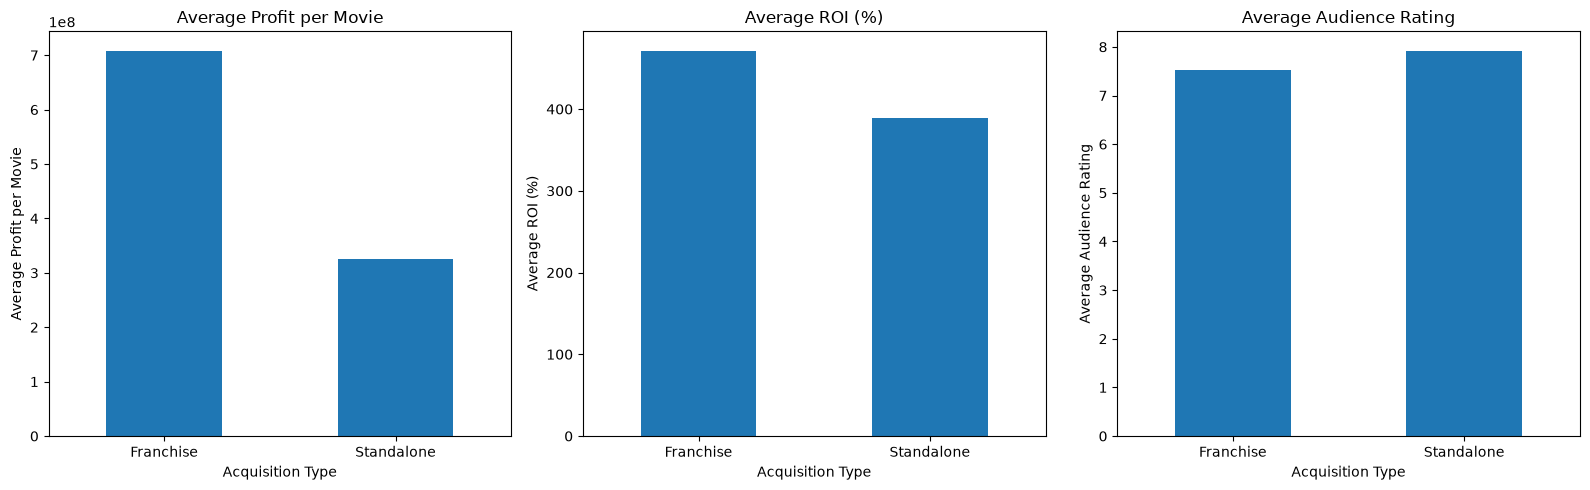

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

modern_comparison = (
    modern_acquisition_units
    .groupby("acquisition_type")
    .agg(
        avg_profit_per_movie=("total_profit", 
                              lambda x: x.sum() / 
                              modern_acquisition_units.loc[
                                  x.index, "movie_count"
                              ].sum()),
        avg_roi=("roi_pct", "mean"),
        avg_rating=("average_rating", "mean")
    )
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("avg_profit_per_movie", "Average Profit per Movie"),
    ("avg_roi", "Average ROI (%)"),
    ("avg_rating", "Average Audience Rating")
]

for ax, (metric, title) in zip(axes, metrics):
    modern_comparison[metric].plot(
        kind="bar",
        ax=ax,
        title=title,
        rot=0
    )
    ax.set_xlabel("Acquisition Type")
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

In [ ]:
###3


In [54]:
# Inspect the cast and crew schemas

print("CAST COLUMNS:")
print(cast.columns.tolist())

print("\nCREW COLUMNS:")
print(crew.columns.tolist())

CAST COLUMNS:
['source_row', 'input_tmdb_id', 'movie_id', 'actor_id', 'actor_name', 'character', 'cast_order']

CREW COLUMNS:
['source_row', 'input_tmdb_id', 'movie_id', 'person_id', 'person_name', 'department', 'job']


In [56]:
print(movies.columns.tolist())

['source_row', 'input_tmdb_id', 'api_movie_id', 'title', 'original_title', 'release_date', 'budget', 'revenue', 'runtime', 'vote_average', 'vote_count', 'popularity', 'original_language', 'status', 'genres', 'collection_id', 'collection_name']


In [64]:
# All standalone acquisition opportunities
all_standalones = (
    modern_units[
        modern_units["acquisition_type"] == "Standalone"
    ]
    .sort_values("core_score", ascending=False)
    .copy()
)

# Exclude the original top 5
original_top5_names = set(
    top_5_standalones["collection_name"]
)

remaining_standalones = all_standalones[
    ~all_standalones["collection_name"].isin(original_top5_names)
]

# Select the next 10
next_10_standalones = remaining_standalones.head(10)

print("Additional standalone opportunities:",
      len(next_10_standalones))

display(
    next_10_standalones[
        [
            "collection_name",
            "movie_count",
            "total_profit",
            "roi_pct",
            "average_rating",
            "core_score"
        ]
    ]
)

Additional standalone opportunities: 7


,collection_name,movie_count,total_profit,roi_pct,average_rating,core_score
22,WALL·E,1,341311860.0,189.617700,8.129,35.517241
25,Memento,1,31060108.0,345.112311,8.175,35.517241
21,The Smurfs,1,453749323.0,412.499385,5.753,30.344828
17,The Departed,1,201465000.0,223.850000,8.160,28.965517
20,The Prestige,1,69676311.0,174.190777,8.212,28.620690
27,Mad Max: Fury Road,1,228858340.0,152.572227,7.642,26.206897
23,Requiem for a Dream,1,2890108.0,64.224622,8.007,17.241379


In [69]:
# 1. Get the three selected franchises directly from final_shortlist
selected_franchises = final_shortlist.loc[
    final_shortlist["acquisition_type"] == "Franchise",
    "collection_name"
].tolist()

# 2. Get the original five standalone opportunities
top_5_standalone_names = top_5_standalones["collection_name"].tolist()

# 3. Get the seven additional standalone opportunities
additional_standalones = next_10_standalones.copy()

additional_standalone_names = (
    additional_standalones["collection_name"].tolist()
)

# 4. Combine all standalone titles
expanded_standalone_names = (
    top_5_standalone_names + additional_standalone_names
)

# 5. Select franchise films
franchise_movies = movies[
    movies["collection_name"].isin(selected_franchises)
].copy()

# 6. Select standalone films
expanded_standalone_movies = movies[
    movies["title"].isin(expanded_standalone_names)
].copy()

# 7. Combine all selected films
talent_analysis_movies = pd.concat(
    [franchise_movies, expanded_standalone_movies],
    ignore_index=True
).drop_duplicates(subset="api_movie_id")

# 8. Standardize identifier
talent_analysis_movies = talent_analysis_movies.rename(
    columns={"api_movie_id": "movie_id"}
)

# 9. Display results
print("Franchise opportunities:", len(selected_franchises))
print("Standalone opportunities:", len(expanded_standalone_names))

print("\nFranchise films:", len(franchise_movies))
print("Standalone films:", len(expanded_standalone_movies))
print("Total selected films:", len(talent_analysis_movies))

display(
    talent_analysis_movies[
        ["movie_id", "title", "collection_name"]
    ].sort_values("title")
)

Franchise opportunities: 3
Standalone opportunities: 12

Franchise films: 15
Standalone films: 12
Total selected films: 27


,movie_id,title,collection_name
14,99861,Avengers: Age of Ultron,The Avengers Collection
4,299534,Avengers: Endgame,The Avengers Collection
8,299536,Avengers: Infinity War,The Avengers Collection
10,672,Harry Potter and the Chamber of Secrets,Harry Potter Collection
9,12444,Harry Potter and the Deathly Hallows: Part 1,Harry Potter Collection
7,12445,Harry Potter and the Deathly Hallows: Part 2,Harry Potter Collection
1,674,Harry Potter and the Goblet of Fire,Harry Potter Collection
13,767,Harry Potter and the Half-Blood Prince,Harry Potter Collection
12,675,Harry Potter and the Order of the Phoenix,Harry Potter Collection
11,671,Harry Potter and the Philosopher's Stone,Harry Potter Collection


In [73]:

# 1. Prepare acquisition-unit information

franchise_names = set(selected_franchises)

talent_movie_info = talent_analysis_movies.copy()

talent_movie_info["acquisition_type"] = talent_movie_info[
    "collection_name"
].apply(
    lambda x: "Franchise" if x in franchise_names else "Standalone"
)

# A franchise is one acquisition unit.
# Each standalone film is its own acquisition unit.
talent_movie_info["acquisition_unit"] = talent_movie_info.apply(
    lambda row: (
        row["collection_name"]
        if row["acquisition_type"] == "Franchise"
        else row["title"]
    ),
    axis=1
)

# 2. Extract the first five credited actors per film

selected_movie_ids = talent_movie_info["movie_id"].unique()

lead_actors = cast[
    cast["movie_id"].isin(selected_movie_ids)
].copy()

lead_actors["cast_order"] = pd.to_numeric(
    lead_actors["cast_order"], errors="coerce"
)

lead_actors = (
    lead_actors
    .sort_values(["movie_id", "cast_order"])
    .groupby("movie_id")
    .head(5)
)

# Attach film and acquisition information
lead_actors = lead_actors.merge(
    talent_movie_info[
        ["movie_id", "title", "acquisition_type", "acquisition_unit"]
    ],
    on="movie_id",
    how="left"
)

# 3. Extract ALL credited directors

directors = crew[
    crew["movie_id"].isin(selected_movie_ids)
].copy()

directors["job"] = directors["job"].fillna("").str.strip()

directors = directors[
    directors["job"].str.lower() == "director"
].copy()

directors = directors.merge(
    talent_movie_info[
        ["movie_id", "title", "acquisition_type", "acquisition_unit"]
    ],
    on="movie_id",
    how="left"
)

# 4. Count directors per movie

directors_per_movie = (
    directors
    .groupby(["movie_id", "title"])
    .agg(
        director_count=("person_id", "nunique"),
        director_names=(
            "person_name",
            lambda x: ", ".join(sorted(set(x.dropna())))
        )
    )
    .reset_index()
    .sort_values("director_count", ascending=False)
)

# 5. Rank actors by acquisition opportunities and films

actor_ranking = (
    lead_actors
    .groupby(["actor_id", "actor_name"])
    .agg(
        film_count=("movie_id", "nunique"),
        acquisition_unit_count=("acquisition_unit", "nunique"),
        films=("title", lambda x: ", ".join(sorted(set(x)))),
        acquisition_units=(
            "acquisition_unit",
            lambda x: ", ".join(sorted(set(x)))
        )
    )
    .reset_index()
    .sort_values(
        ["acquisition_unit_count", "film_count"],
        ascending=False
    )
)

top_5_actors = actor_ranking.head(5).copy()

# 6. Rank directors by acquisition opportunities and films

director_ranking = (
    directors
    .groupby(["person_id", "person_name"])
    .agg(
        film_count=("movie_id", "nunique"),
        acquisition_unit_count=("acquisition_unit", "nunique"),
        films=("title", lambda x: ", ".join(sorted(set(x)))),
        acquisition_units=(
            "acquisition_unit",
            lambda x: ", ".join(sorted(set(x)))
        )
    )
    .reset_index()
    .sort_values(
        ["acquisition_unit_count", "film_count"],
        ascending=False
    )
)

top_5_directors = director_ranking.head(5).copy()

# 7. Display extraction results

print("========== TALENT EXTRACTION ==========")

print("\nSelected films:", len(talent_movie_info))

print("Lead actor records:", len(lead_actors))
print("Unique lead actors:", lead_actors["actor_id"].nunique())

print("\nDirector records:", len(directors))
print("Unique directors:", directors["person_id"].nunique())

print("\n========== DIRECTORS PER MOVIE ==========")

display(directors_per_movie)

print("\n========== TOP 5 LEAD ACTORS ==========")

display(top_5_actors)

print("\n========== TOP 5 DIRECTORS ==========")

display(top_5_directors)


========== TALENT EXTRACTION ==========

Selected films: 27
Lead actor records: 135
Unique lead actors: 84

Director records: 29
Unique directors: 17

========== DIRECTORS PER MOVIE ==========


,movie_id,title,director_count,director_names
12,299534,Avengers: Endgame,2,"Anthony Russo, Joe Russo"
13,299536,Avengers: Infinity War,2,"Anthony Russo, Joe Russo"
0,10681,WALL·E,1,Andrew Stanton
3,121,The Lord of the Rings: The Two Towers,1,Peter Jackson
4,122,The Lord of the Rings: The Return of the King,1,Peter Jackson
5,12444,Harry Potter and the Deathly Hallows: Part 1,1,David Yates
6,12445,Harry Potter and the Deathly Hallows: Part 2,1,David Yates
7,129,Spirited Away,1,Hayao Miyazaki
8,1422,The Departed,1,Martin Scorsese
1,1124,The Prestige,1,Christopher Nolan



========== TOP 5 LEAD ACTORS ==========


,actor_id,actor_name,film_count,acquisition_unit_count,films,acquisition_units
40,2524,Tom Hardy,2,2,"Inception, Mad Max: Fury Road","Inception, Mad Max: Fury Road"
48,3895,Michael Caine,2,2,"Interstellar, The Prestige","Interstellar, The Prestige"
67,6193,Leonardo DiCaprio,2,2,"Inception, The Departed","Inception, The Departed"
4,10980,Daniel Radcliffe,8,1,"Harry Potter and the Chamber of Secrets, Harry...",Harry Potter Collection
5,10989,Rupert Grint,8,1,"Harry Potter and the Chamber of Secrets, Harry...",Harry Potter Collection



========== TOP 5 DIRECTORS ==========


,person_id,person_name,film_count,acquisition_unit_count,films,acquisition_units
12,525,Christopher Nolan,4,4,"Inception, Interstellar, Memento, The Prestige","Inception, Interstellar, Memento, The Prestige"
5,11343,David Yates,4,1,"Harry Potter and the Deathly Hallows: Part 1, ...",Harry Potter Collection
2,108,Peter Jackson,3,1,The Lord of the Rings: The Fellowship of the R...,The Lord of the Rings Collection
3,10965,Chris Columbus,2,1,"Harry Potter and the Chamber of Secrets, Harry...",Harry Potter Collection
8,12891,Joss Whedon,2,1,"Avengers: Age of Ultron, The Avengers",The Avengers Collection
